# Klasifikasi Gambar Rock-Paper-Scissors dengan CNN
![Python](https://img.shields.io/badge/Python-3.11-blue)
![TensorFlow](https://img.shields.io/badge/TensorFlow-2.15-orange)
![License](https://img.shields.io/badge/License-MIT-green)

**Proyek Akhir — Kelas *Belajar Machine Learning untuk Pemula* (Dicoding)** <br/>
Muhammad Erlangga Gunawan 

---

## Daftar Isi

1. [Latar Belakang & Tujuan](#1-latar-belakang--tujuan)
2. [Dataset](#2-dataset)
3. [Data Preparation](#3-data-preparation)
4. [Arsitektur Model](#4-arsitektur-model)
5. [Training](#5-training)
6. [Evaluasi](#6-evaluasi)
7. [Export & Deployment](#7-export--deployment)
8. [Demo Prediksi](#8-demo-prediksi)
9. [Kesimpulan & Limitasi](#9-kesimpulan--limitasi)
10. [Referensi](#10-referensi)

## Ringkasan Hasil

| Metrik | Nilai |
|---|---|
| Total data | 2.188 gambar (3 kelas) |
| Split train / validasi | 60% / 40% (1.314 / 874 gambar) |
| Akurasi training (epoch terakhir) | 98,55% |
| Akurasi validasi (dihitung ulang) | 97.14% |
| Target validasi ≥ 85% | tercapai (97.14% > 85%) |
| Kelas yang pernah diprediksi | 3 dari 3 (dari output sel 14: (1) distribusi prediksi validasi : [272, 296, 306] — semua 3 kelas terpakai) |
| Jumlah parameter | 110,819 |
| Format model diekspor | SavedModel, TF-Lite, TFJS |

**Pendekatan:** CNN dari nol (3 blok `Conv2D + BatchNormalization(momentum=0.9) + ReLU + MaxPooling`,
diikuti `GlobalAveragePooling2D` → `Dropout(0.5)` → `Dense`), dilatih dengan augmentasi ringan
dan tiga callback yang semuanya memantau `val_loss`.

> **Catatan iterasi.** Run pertama kolaps pada data validasi: hanya satu kelas yang diprediksi
> (`[0, 874, 0]`), akurasi validasi beku di 33,18% karena `EarlyStopping` + `restore_best_weights`
> mengembalikan bobot epoch 1. Perbaikannya dijelaskan pada bagian 4 dan 5, dan hasil akhirnya
> adalah angka pada tabel di atas.

## Cara Menjalankan Notebook

**Di Google Colab (rekomendasi untuk training penuh — gratis GPU/CPU cepat):**
1. `Runtime → Change runtime type` (GPU jika tersedia, tapi CPU sudah memadai untuk dataset ini).
2. `Runtime → Run all`. Dataset diunduh otomatis (~308 MB) lalu diekstrak ke `/content`.

**Di lokal dengan `uv` (Windows/macOS/Linux):**<br/>
<br/>
uv init --python 3.11
uv venv --python 3.11
uv add "tensorflow==2.15.*" matplotlib numpy scikit-learn pillow
uv add --dev jupyterlab ipykernel nbqa ruff
uv add tensorflowjs
uv run python -m ipykernel install --user --name klasifikasi-gambar --display-name "Python (Klasifikasi Gambar)"
uv run jupyter lab

Lalu pilih kernel **Python (Klasifikasi Gambar)**. Tanpa Colab, dataset diunduh ke folder kerja saat ini.

### Troubleshooting

| Gejala | Penyebab & solusi |
|---|---|
| `ImportError: cannot import name 'ImageDataGenerator'` | TensorFlow ≥ 2.16 memakai Keras 3. Pakai `tensorflow==2.15.*` (Python ≤ 3.11), atau `pip install tf-keras` lalu `from tf_keras.preprocessing.image import ImageDataGenerator`. |
| `Unrecognized keyword arguments: ['input_shape']` | Keras 3 tidak menerima `input_shape` di layer. Notebook ini sudah memakai `tf.keras.Input(...)`. |
| `tensorflowjs_converter: command not found` | Jalankan `pip install tensorflowjs` lalu **restart runtime**, atau lewati sel TFJS dan konversi manual di terminal. |
| Training lambat di Windows | TensorFlow Windows hanya CPU. Develop di lokal, jalankan training penuh di Colab. |

## 1. Latar Belakang & Tujuan

**Masalah.** Pengenalan gestur tangan adalah komponen penting pada antarmuka tanpa sentuhan
(touchless UI), permainan berbasis kamera, dan sistem bantuan untuk penyandang disabilitas.
Salah satu kasus paling dasar dan mudah divalidasi adalah **Rock–Paper–Scissors**: tiga kelas
gestur yang bentuknya berbeda jelas, sehingga cocok untuk mengukur kualitas pipeline klasifikasi
gambar dari awal sampai deployment.

**Tujuan.**
1. Membangun model CNN yang mengklasifikasi gambar gestur tangan ke tiga kelas: `paper`, `rock`, `scissors`.
2. Mencapai akurasi ≥ 85% pada data training **dan** data validasi.
3. Menyimpan model ke tiga format siap produksi: **SavedModel**, **TF-Lite**, dan **TFJS**.
4. Menyediakan demo inferensi pada gambar yang diunggah pengguna.

**Batasan.** Model hanya mengenali gestur dengan latar polos dan pencahayaan wajar
(dataset publik). Input diperkecil ke 150×150 piksel, dan hanya satu tangan per gambar.

## 2. Dataset
Sumber: `[https://github.com/dicodingacademy/assets/releases/download/release/rockpaperscissors.zip](https://github.com/dicodingacademy/assets/releases/download/release/rockpaperscissors.zip)` (berasal dari dataset publik *Rock Paper Scissors* karya Laurence Moroney).

Setelah diekstrak, struktur foldernya:

```text
rockpaperscissors/
├── paper/              # gambar asli (belum di-crop)
├── rock/
├── scissors/
└── rps-cv-images/      # versi yang sudah diproses/di-crop, 300×200 px
    ├── paper/
    ├── rock/
    └── scissors/
```

**Notebook ini melatih model pada `rps-cv-images`**, karena versi tersebut sudah dinormalisasi (objek terpusat, latar bersih) sehingga model lebih cepat konvergen dan hasil antar-run lebih stabil. Semua statistik dan EDA di bawah dihitung dari folder yang sama dengan yang dipakai training, supaya angka pada narasi benar-benar merepresentasikan data yang dilatih.

> **Catatan lisensi.** Dataset digunakan untuk keperluan edukasi; cantumkan sumber aslinya apabila gambar dipakai ulang di luar konteks tugas ini.

### Setup & versi

In [1]:
# =============================================================
# Setup: import seluruh library + cek versi untuk reproduksibilitas
# =============================================================
import random
import shutil
import subprocess
import sys
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)

# Kompatibel TF 2.15 (Keras 2) dan TF >= 2.16 (Keras 3)
try:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except ImportError:  # Keras 3: ImageDataGenerator hanya ada di paket tf-keras
    import subprocess
    import sys as _sys

    subprocess.run(
        [_sys.executable, "-m", "pip", "install", "-q", "tf-keras"], check=True
    )
    from tf_keras.preprocessing.image import ImageDataGenerator

    print("Catatan: memakai tf_keras.preprocessing.image (Keras 3).")

# Versi dicetak agar hasil bisa direproduksi (catat di README)
print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)


Python     : 3.11.9
TensorFlow : 2.15.1
NumPy      : 1.26.4


### Konfigurasi global

In [2]:
# =============================================================
# Konfigurasi global
# Semua "angka ajaib" dikumpulkan di sini agar mudah diubah
# =============================================================
SEED = 42  # seed tunggal untuk numpy, python, tensorflow
IMG_SIZE = (150, 150)  # ukuran input model (px)
BATCH = 32  # batch size; jumlah step/epoch dihitung otomatis oleh Keras
VAL_SPLIT = 0.4  # 40% data untuk validasi (ketentuan tugas)
EPOCHS = 40  # batas atas; EarlyStopping akan berhenti lebih cepat

# --- Hyperparameter yang diperbaiki setelah analisis run pertama ---
# Run v1 (LR 1e-3 + BN momentum 0.99) kolaps: val_accuracy mentok 33.18%
# (= 290/874, hanya memprediksi "rock") sementara train 96.58%.
LR = 5e-4  # diturunkan dari 1e-3: lebih aman bila memakai BatchNorm
USE_BN = True  # set False bila val_accuracy masih mentok setelah 3 epoch
BN_MOMENTUM = 0.9  # default 0.99 terlalu lambat untuk 42 step/epoch
DROPOUT = 0.5  # dinaikkan dari 0.3 (dataset kecil, 2.188 gambar)
MIN_VAL_ACC = 0.85  # ambang minimal ketentuan tugas
STRICT_VALIDATION = False  # True: notebook berhenti keras bila target tidak tercapai
DIAG_EACH_EPOCH = True  # cetak distribusi prediksi validasi tiap epoch

# Deteksi lingkungan: Colab memakai /content, lokal memakai folder kerja saat ini
IS_COLAB = Path("/content").exists()
ROOT = Path("/content") if IS_COLAB else Path.cwd()

DATA_ROOT = ROOT / "rockpaperscissors"
DATA_DIR = DATA_ROOT / "rps-cv-images"  # folder yang dipakai training
MODELS_DIR = ROOT / "models"
SAMPLES_DIR = ROOT / "assets" / "samples"  # gambar contoh untuk demo offline

for folder in (MODELS_DIR, SAMPLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Seed global -> hasil training lebih dapat direproduksi
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print("Lingkungan :", "Google Colab" if IS_COLAB else "Lokal")
print("Folder data:", DATA_DIR)
print("Folder model:", MODELS_DIR)
print(f"LR={LR} | BN={USE_BN} (momentum={BN_MOMENTUM}) | Dropout={DROPOUT}")

Lingkungan : Lokal
Folder data: c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\rockpaperscissors\rps-cv-images
Folder model: c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\models
LR=0.0005 | BN=True (momentum=0.9) | Dropout=0.5


### Unduh & ekstrak dataset

In [3]:
# =============================================================
# Mengunduh & mengekstrak dataset (portabel: Colab maupun lokal)
# =============================================================
DATA_URL = "https://github.com/dicodingacademy/assets/releases/download/release/rockpaperscissors.zip"
ZIP_PATH = ROOT / "rockpaperscissors.zip"

if DATA_DIR.exists():
    print("Dataset sudah tersedia, unduhan dilewati.")
else:
    if not ZIP_PATH.exists():
        print("Mengunduh dataset (~308 MB) ...")
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
        print(f"Selesai: {ZIP_PATH.stat().st_size / 1e6:.0f} MB")

    print("Mengekstrak arsip ...")
    shutil.unpack_archive(str(ZIP_PATH), str(ROOT))

# Sanity check: pastikan folder yang dipakai benar-benar ada
assert DATA_DIR.exists(), f"Folder data tidak ditemukan: {DATA_DIR}"
print("Isi folder dataset:", sorted(p.name for p in DATA_ROOT.iterdir()))

Dataset sudah tersedia, unduhan dilewati.
Isi folder dataset: ['README_rpc-cv-images.txt', 'paper', 'rock', 'rps-cv-images', 'scissors']


### Statistik per kelas

In [4]:
# =============================================================
# Data understanding: jumlah gambar per kelas
# Dihitung dari DATA_DIR yang sama dengan yang dipakai training
# =============================================================
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp"}

class_counts = {}
for class_dir in sorted(d for d in DATA_DIR.iterdir() if d.is_dir()):
    files = [f for f in class_dir.iterdir() if f.suffix.lower() in IMG_EXT]
    class_counts[class_dir.name] = len(files)

total = sum(class_counts.values())
print(f"Total gambar: {total}")
for name, count in class_counts.items():
    print(f"  {name:<10}: {count:>5} gambar ({count / total:.1%})")

Total gambar: 2188
  paper     :   712 gambar (32.5%)
  rock      :   726 gambar (33.2%)
  scissors  :   750 gambar (34.3%)


### Contoh gambar per kelas

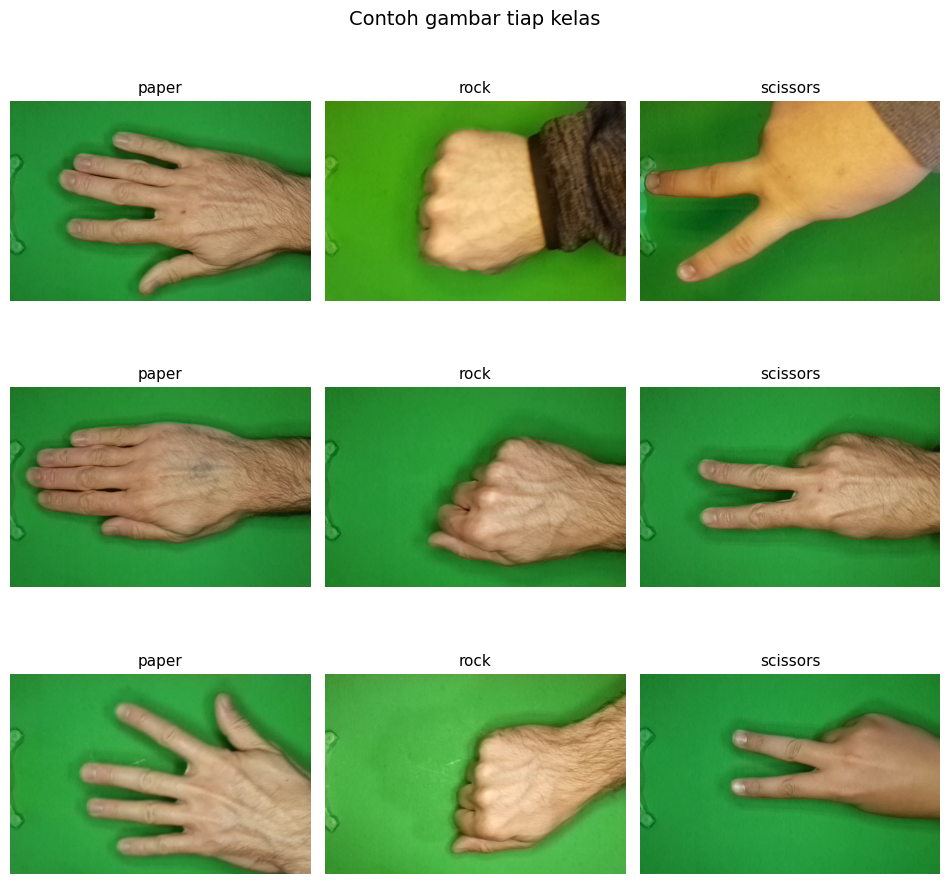

In [5]:
# =============================================================
# Menampilkan contoh gambar tiap kelas dalam grid
# =============================================================
def show_samples(n_per_class=3, seed=SEED):
    """Menampilkan grid contoh gambar: baris = gambar ke-n, kolom = kelas."""
    rng = random.Random(seed)  # RNG terpisah agar tidak mengganggu seed training
    fig, axes = plt.subplots(
        n_per_class,
        len(class_counts),
        figsize=(3.2 * len(class_counts), 3.2 * n_per_class),
    )

    for col, class_name in enumerate(class_counts):
        files = sorted(
            f for f in (DATA_DIR / class_name).iterdir() if f.suffix.lower() in IMG_EXT
        )
        for row, path in enumerate(rng.sample(files, n_per_class)):
            ax = axes[row, col]
            ax.imshow(plt.imread(path))
            ax.axis("off")
            ax.set_title(class_name, fontsize=11)

    fig.suptitle("Contoh gambar tiap kelas", fontsize=14)
    plt.tight_layout()
    plt.show()


show_samples()

### Distribusi kelas

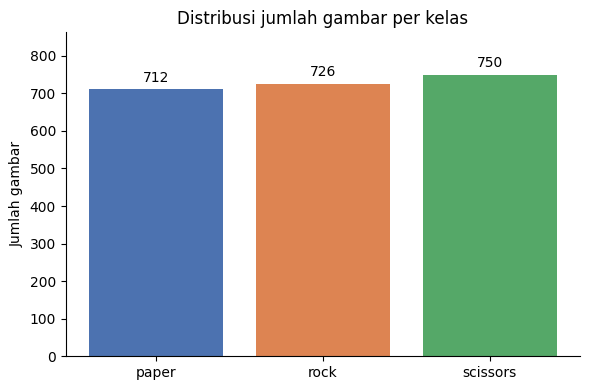

Selisih kelas terbanyak vs tersedikit: 38 gambar (1.7% dari total) -> dataset seimbang.


In [6]:
# =============================================================
# Diagram batang distribusi kelas (cek keseimbangan dataset)
# =============================================================
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    class_counts.keys(), class_counts.values(), color=["#4C72B0", "#DD8452", "#55A868"]
)
ax.bar_label(bars, fmt="%d", padding=3)
ax.set_title("Distribusi jumlah gambar per kelas")
ax.set_ylabel("Jumlah gambar")
ax.set_ylim(0, max(class_counts.values()) * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

selisih = max(class_counts.values()) - min(class_counts.values())
print(
    f"Selisih kelas terbanyak vs tersedikit: {selisih} gambar "
    f"({selisih / total:.1%} dari total) -> dataset seimbang."
)

## 3. Data Preparation

#### 3.1. Pembagian data: 60% training — 40% validasi

Pembagian dilakukan **per kelas** menggunakan `validation_split=0.4` pada `ImageDataGenerator`,
sehingga proporsi tiap kelas tetap terjaga di kedua subset (stratified otomatis).

**Dua generator dibuat terpisah — ini penting:**

| Generator | `rescale` | Augmentasi | `shuffle` | Alasan |
|---|---|---|---|---|
| `train_gen` | ✅ | ✅ | ✅ | Model harus melihat variasi gambar sebanyak mungkin |
| `val_gen` | ✅ | ❌ | ❌ | Metrik validasi harus deterministik & bisa dibandingkan antar-epoch |

Menggunakan generator yang sama (ber-augmentasi) untuk validasi membuat `val_loss` berubah-ubah
tanpa alasan, sehingga kita tidak bisa tahu kapan model benar-benar membaik, dan tidak bisa
menghitung confusion matrix dengan urutan yang benar.

3.2. Augmentasi gambar <br/>
Dataset hanya ~2.200 gambar, jadi augmentasi tetap dipakai — tetapi **ringan**. Versi pertama
memakai rotasi 40°+shear 0.2 dan justru memperlebar jarak antara data training dan validasi,
karena `rps-cv-images` sudah di-crop dengan objek terpusat dan latar polos.

| Parameter | Nilai | Alasan |
|---|---|---|
| `rotation_range` | 15 | tangan pada dataset hampir selalu tegak; 40° membuat gestur tidak wajar |
| `zoom_range` | 0.1 | variasi jarak kamera, tanpa memotong jari |
| `width/height_shift_range` | 0.1 | variasi posisi tangan di frame |
| `shear_range` | — (dihapus) | memiringkan kontur tangan, tidak realistis untuk gestur |
| `horizontal_flip` | `True` | aman: `rock`, `paper`, `scissors` tetap bermakna saat dicerminkan |
| `fill_mode` | `nearest` | piksel tepi diisi nilai terdekat saat gambar digeser/diputar |


3.3 Jumlah step 
<br/>
`steps_per_epoch` **tidak** di-hardcode. Keras menghitungnya dengan pembulatan ke atas
(`ceil(jumlah_gambar / batch_size)`), sehingga seluruh data terpakai setiap epoch:
**42 step training** (1.314 gambar) dan **28 step validasi** (874 gambar).

### Generator

In [7]:
# =============================================================
# Image data generator
# train: rescale + augmentasi ringan | validasi: rescale saja
# validation_split HARUS sama di kedua generator agar pembagiannya identik
# =============================================================
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    # --- augmentasi diringankan: dataset sudah bersih & terpusat ---
    rotation_range=15,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest",
    validation_split=VAL_SPLIT,
)

# Validasi TIDAK boleh diaugmentasi: metrik harus deterministik antar-epoch
val_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=VAL_SPLIT,
)

train_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=SEED,
)

val_gen = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    subset="validation",
    shuffle=False,  # WAJIB False agar urutan prediksi == urutan label asli
    seed=SEED,
)

Found 1314 images belonging to 3 classes.
Found 874 images belonging to 3 classes.


### Ringkasan generator & mapping label

In [8]:
# =============================================================
# Ringkasan generator + pemetaan indeks -> nama kelas
# Label TIDAK di-hardcode: diambil dari train_gen.class_indices
# (urutan alfabetis -> paper=0, rock=1, scissors=2)
# =============================================================
LABELS = {index: name for name, index in train_gen.class_indices.items()}
print("Pemetaan kelas:", LABELS)
# ceil, bukan floor: Keras memakai 42 step walau 1314 // 32 = 41
print(
    f"Training : {train_gen.samples:>4} gambar -> {int(np.ceil(train_gen.samples / BATCH))} step/epoch"
)
print(
    f"Validasi : {val_gen.samples:>4} gambar -> {int(np.ceil(val_gen.samples / BATCH))} step/epoch"
)
assert set(train_gen.class_indices) == set(val_gen.class_indices), (
    "Daftar kelas train != validasi"
)

Pemetaan kelas: {0: 'paper', 1: 'rock', 2: 'scissors'}
Training : 1314 gambar -> 42 step/epoch
Validasi :  874 gambar -> 28 step/epoch


### Visualisasi augmentasi

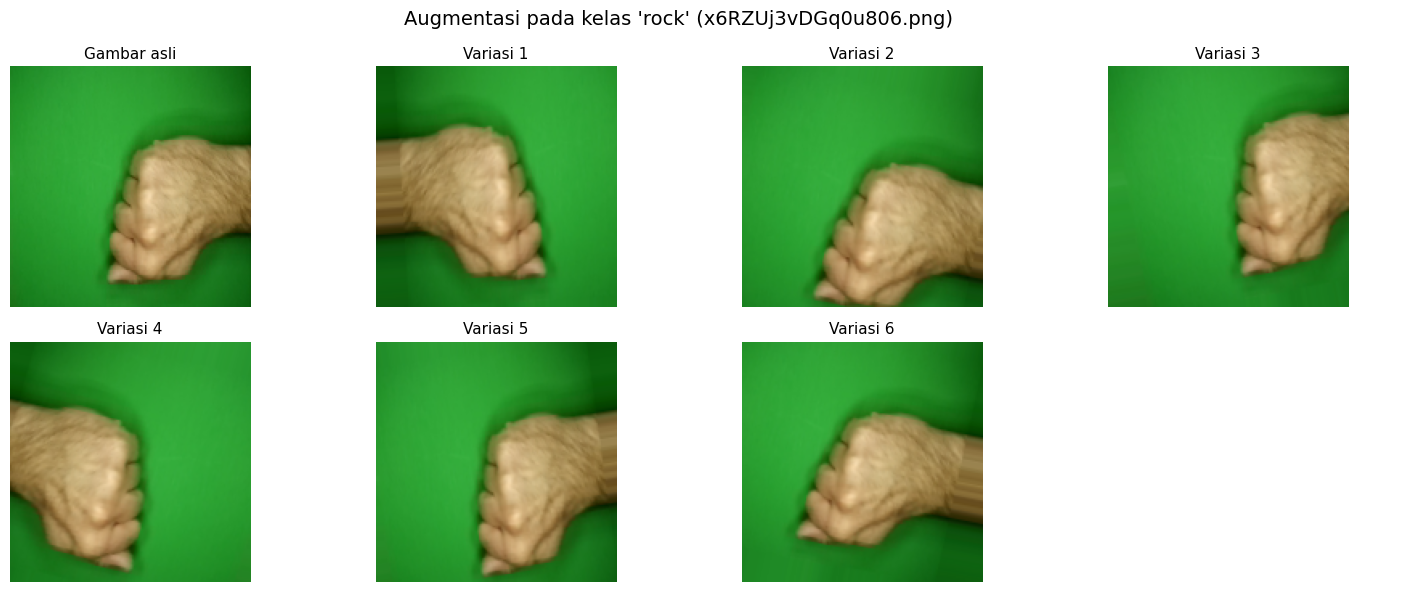

In [9]:
# =============================================================
# Memastikan augmentasi bekerja: 1 gambar -> beberapa versi augmentasi
# =============================================================
def show_augmentation(target_class="rock", n_aug=6, seed=SEED):
    rng = random.Random(seed)
    files = sorted(
        f for f in (DATA_DIR / target_class).iterdir() if f.suffix.lower() in IMG_EXT
    )
    path = rng.choice(files)

    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    # Simpan dalam rentang 0-255: rescale 1/255 akan dilakukan oleh generator
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), axis=0)

    fig, axes = plt.subplots(2, (n_aug + 2) // 2, figsize=(15, 6))
    axes = axes.ravel()

    axes[0].imshow(img)
    axes[0].set_title("Gambar asli", fontsize=11)
    axes[0].axis("off")

    aug_iter = train_datagen.flow(arr, batch_size=1, seed=seed)
    for i in range(1, n_aug + 1):
        augmented = next(aug_iter)[0]
        axes[i].imshow(np.clip(augmented, 0, 1))
        axes[i].set_title(f"Variasi {i}", fontsize=11)
        axes[i].axis("off")

    for ax in axes[n_aug + 1 :]:
        ax.axis("off")

    fig.suptitle(f"Augmentasi pada kelas '{target_class}' ({path.name})", fontsize=14)
    plt.tight_layout()
    plt.show()


show_augmentation()

## 4 Arsitektur Model

Model dibangun **dari nol** (bukan transfer learning) memakai `tf.keras.Sequential`:

| Blok | Layer | Fungsi |
|---|---|---|
| 1 | `Conv2D(32) + BatchNorm + ReLU + MaxPool` | Menangkap pola tepi & kontur sederhana |
| 2 | `Conv2D(64) + BatchNorm + ReLU + MaxPool` | Menangkap bentuk jari/telapak |
| 3 | `Conv2D(128) + BatchNorm + ReLU + MaxPool` | Menangkap gestur utuh |
| 4 | `GlobalAveragePooling2D` | Meringkas tiap feature map menjadi 1 angka |
| 5 | `Dropout(0.5)` | Regularisasi utama pada classifier |
| 6 | `Dense(128) + ReLU` | Kombinasi fitur tingkat tinggi |
| 7 | `Dense(3) + Softmax` | Probabilitas 3 kelas |

**Catatan hasil iterasi (penting):**

- Run pertama memakai `BatchNormalization` dengan `momentum` default **0.99**. Dengan hanya
  **42 step/epoch**, rata-rata bergerak (running mean/varian) yang dipakai saat *inference*
  belum mengikuti distribusi data sebenarnya, sehingga model memprediksi satu kelas untuk semua
  gambar validasi. Karena `val_accuracy` beku sejak epoch 1, `EarlyStopping` +
  `restore_best_weights` justru mengembalikan bobot **epoch 1**.
- Perbaikan: `momentum=0.9`, learning rate **5e-4**, dan pemantauan per-epoch
  distribusi prediksi untuk mendeteksi kolaps lebih dini. `USE_BN = False` disediakan sebagai
  jalan keluar bila gejala yang sama muncul lagi.
- `use_bias=False` pada `Conv2D` bila layer diikuti `BatchNormalization` (bias redundant).

**Alasan pemilihan lain:**

- **`padding='same'`** menjaga resolusi spasial sampai pooling terakhir.
- **`GlobalAveragePooling2D`** menggantikan `Flatten + Dense(512)`: parameter turun dari
  ~1,27 juta menjadi ~110 ribu (≈12× lebih kecil), menurunkan risiko overfit dan membuat
  model jauh lebih ringan untuk TF-Lite.
- **Filter bertambah (32 → 64 → 128)** mengikuti praktik umum CNN.

### Build model

In [10]:
# =============================================================
# Membangun model CNN
# Layer pertama memakai tf.keras.Input (wajib di Keras 3 / TF >= 2.16)
# USE_BN=False -> arsitektur identik tanpa BatchNormalization
# =============================================================
def conv_block(filters, name):
    """Conv2D (+BatchNorm opsional) -> ReLU -> MaxPooling2D."""
    layers = [
        tf.keras.layers.Conv2D(
            filters,
            (3, 3),
            padding="same",
            use_bias=not USE_BN,  # bias redundant bila ada BatchNorm
            name=f"{name}_conv",
        )
    ]
    if USE_BN:
        # momentum 0.9 (default 0.99) agar running stats mengikuti 42 step/epoch
        layers.append(
            tf.keras.layers.BatchNormalization(
                momentum=BN_MOMENTUM, epsilon=1e-3, name=f"{name}_bn"
            )
        )
    layers += [
        tf.keras.layers.Activation("relu", name=f"{name}_relu"),
        tf.keras.layers.MaxPooling2D((2, 2), name=f"{name}_pool"),
    ]
    return layers


def build_model(input_shape=(*IMG_SIZE, 3), num_classes=3):
    return tf.keras.Sequential(
        [
            tf.keras.Input(shape=input_shape, name="input_image"),
            # Blok 1: pola sederhana (tepi, kontur)
            *conv_block(32, "block1"),
            # Blok 2: bentuk jari/telapak
            *conv_block(64, "block2"),
            # Blok 3: gestur utuh
            *conv_block(128, "block3"),
            # Classifier head
            tf.keras.layers.GlobalAveragePooling2D(name="gap"),
            tf.keras.layers.Dropout(DROPOUT, name="dropout"),
            tf.keras.layers.Dense(128, activation="relu", name="fc"),
            tf.keras.layers.Dense(
                num_classes, activation="softmax", name="output_probs"
            ),
        ],
        name="rps_cnn",
    )


model = build_model(num_classes=len(class_counts))
model.summary()



Model: "rps_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 block1_conv (Conv2D)        (None, 150, 150, 32)      864       
                                                                 
 block1_bn (BatchNormalizat  (None, 150, 150, 32)      128       
 ion)                                                            
                                                                 
 block1_relu (Activation)    (None, 150, 150, 32)      0         
                                                                 
 block1_pool (MaxPooling2D)  (None, 75, 75, 32)        0         
                                                                 
 block2_conv (Conv2D)        (None, 75, 75, 64)        18432     
                                                                 
 block2_bn (BatchNormalizat  (None, 75, 75, 64)        256       
 ion)                                                    

### Compile

In [11]:
# =============================================================
# Kompilasi model
# categorical_crossentropy karena label dari generator one-hot
# LR diambil dari konfigurasi global (5e-4, bukan 1e-3)
# =============================================================
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
print(f"Model siap dilatih (lr={LR}).")

Model siap dilatih (lr=0.0005).


## 5. Training
Tiga callback Training + satu logger diagnostik dipakai agar training efisien dan hasil akhirnya adalah model **terbaik** menurut
`val_loss` (bukan `val_accuracy`):

| Callback | Monitor | Peran |
|---|---|---|
| `EarlyStopping` | `val_loss` (min), `patience=12`, `min_delta=1e-3` | Berhenti saat loss validasi benar-benar tidak membaik |
| `ReduceLROnPlateau` | `val_loss` (min), `factor=0.3`, `patience=4` | Menurunkan LR saat loss stagnan |
| `ModelCheckpoint` | `val_loss` (min) | Menyimpan bobot terbaik ke `models/best.keras` |
| `ValDistributionLogger` | — | Mencetak distribusi prediksi validasi **tiap epoch** |

**Kenapa `val_loss`, bukan `val_accuracy`?** Akurasi bersifat "tangga": pada kasus ekstrem ia bisa
beku di satu nilai (mis. `0.3318`) selama sembilan epoch, sehingga `EarlyStopping` mengira tidak ada
kemajuan dan `restore_best_weights` mengembalikan **epoch 1**. `val_loss` berubah secara kontinu
sehingga jauh lebih peka terhadap kemajuan maupun kemunduran.

`ValDistributionLogger` adalah pengaman tambahan: model yang kolaps ke satu kelas akan langsung
terlihat dari distribusi prediksi (mis. `[0, 874, 0]`) walaupun akurasinya tampak "wajar" ~33%.

Setelah `fit`, model **dimuat ulang** dari `models/best.keras` agar bobot yang diekspor dijamin
sama dengan yang dilaporkan.

`steps_per_epoch` dan `validation_steps` **tidak** diisi: Keras menghitung 42 step training dan
28 step validasi.

### Callback + fit

In [12]:
# =============================================================
# Training dengan callbacks + pemantauan distribusi prediksi
# =============================================================
BEST_MODEL_PATH = MODELS_DIR / "best.keras"


class ValDistributionLogger(tf.keras.callbacks.Callback):
    """Cetak distribusi prediksi validasi di akhir setiap epoch.

    Tujuan: mendeteksi dini 'mode collapse' (model memprediksi satu kelas saja).
    Kasus seperti ini bisa lolos dari akurasi agregat, karena memprediksi satu
    kelas pada dataset seimbang tetap menghasilkan akurasi ~33%.
    """

    def __init__(self, val_gen, labels):
        super().__init__()
        self.val_gen = val_gen
        self.labels = labels

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.val_gen, verbose=0)
        pred = np.argmax(probs, axis=1)
        counts = np.bincount(pred, minlength=len(self.labels)).tolist()
        n_used = sum(c > 0 for c in counts)
        confidence = probs.max(axis=1).mean()
        print(
            f"  [diagnostik] prediksi validasi: {counts} "
            f"({n_used}/{len(self.labels)} kelas terpakai, "
            f"confidence rata-rata {confidence:.1%})"
        )
        if n_used == 1:
            print(
                "  [PERINGATAN] hanya SATU kelas diprediksi -> periksa BatchNorm / mode eval"
            )


callbacks = [
    # Monitor val_loss: sinyalnya kontinu, tidak "beku" seperti akurasi
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=12,
        min_delta=1e-3,
        restore_best_weights=True,
        verbose=1,
    ),
    # LR diturunkan hanya jika loss benar-benar stagnan (factor 0.3, bukan 0.5)
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
]

if DIAG_EACH_EPOCH:
    callbacks.append(ValDistributionLogger(val_gen, LABELS))

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=2,
)

# Jaminan eksplisit: artefak yang diekspor = bobot terbaik (val_loss terendah)
model = tf.keras.models.load_model(BEST_MODEL_PATH)

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
best_val_acc = max(history.history["val_accuracy"])
print(f"\nEpoch terbaik (val_loss terendah): {best_epoch}")
print(f"Akurasi training epoch terakhir  : {history.history['accuracy'][-1]:.2%}")
print(
    f"Akurasi validasi pada epoch itu  : {history.history['val_accuracy'][best_epoch - 1]:.2%}"
)
print(f"Akurasi validasi terbaik (run)   : {best_val_acc:.2%}")
print("Model di memori = bobot terbaik dari models/best.keras")

Epoch 1/40



Epoch 1: val_loss improved from inf to 1.33776, saving model to c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\models\best.keras
  [diagnostik] prediksi validasi: [0, 638, 236] (2/3 kelas terpakai, confidence rata-rata 54.0%)
42/42 - 41s - loss: 0.9377 - accuracy: 0.5510 - val_loss: 1.3378 - val_accuracy: 0.4611 - lr: 5.0000e-04 - 41s/epoch - 978ms/step
Epoch 2/40

Epoch 2: val_loss did not improve from 1.33776
  [diagnostik] prediksi validasi: [739, 130, 5] (3/3 kelas terpakai, confidence rata-rata 82.8%)
42/42 - 29s - loss: 0.6467 - accuracy: 0.7428 - val_loss: 1.4176 - val_accuracy: 0.4542 - lr: 5.0000e-04 - 29s/epoch - 685ms/step
Epoch 3/40

Epoch 3: val_loss improved from 1.33776 to 0.65553, saving model to c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\models\best.keras
  [diagnostik] prediksi validasi: [341, 62, 471] (3/3 kelas terpakai, confidence rata-rata 77.2%)
42/42 - 31s - loss: 0.4981 - accuracy: 0.8387 - val_loss: 0.6555 - val_ac

### Kurva training

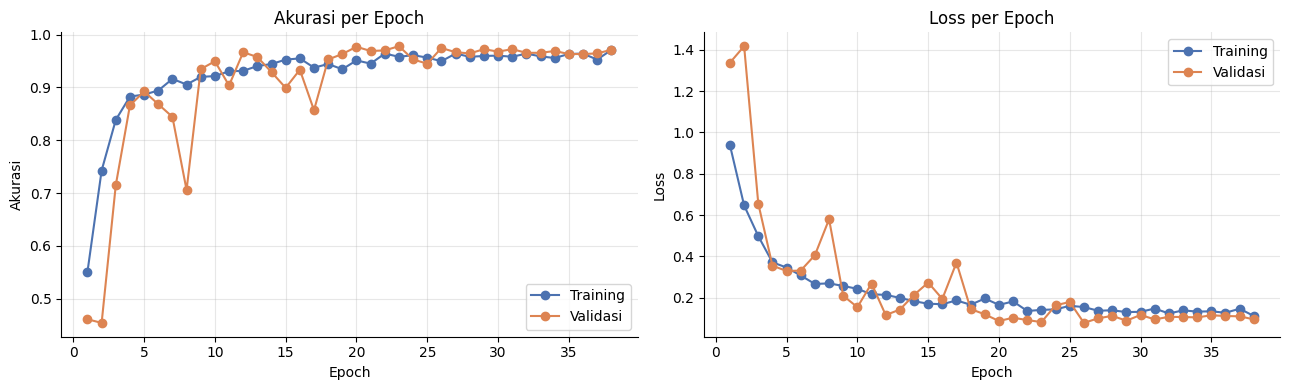

Interpretasi: bila kurva training terus naik sementara validasi mendatar/turun -> overfit.


In [13]:
# =============================================================
# Kurva akurasi & loss: mendeteksi overfit / underfit
# =============================================================
h = history.history
epochs_range = range(1, len(h["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_range, h["accuracy"], "o-", label="Training", color="#4C72B0")
axes[0].plot(epochs_range, h["val_accuracy"], "o-", label="Validasi", color="#DD8452")
axes[0].set_title("Akurasi per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Akurasi")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, h["loss"], "o-", label="Training", color="#4C72B0")
axes[1].plot(epochs_range, h["val_loss"], "o-", label="Validasi", color="#DD8452")
axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(
    "Interpretasi: bila kurva training terus naik sementara validasi mendatar/turun -> overfit."
)

## 6. Evaluasi

Selain akurasi agregat, evaluasi memakai dua alat bantu:

- **Classification report** — precision, recall, dan F1 per kelas. Berguna karena akurasi tinggi
  bisa menyembunyikan satu kelas yang sering tertukar.
- **Confusion matrix** — menunjukkan pasangan kelas mana yang paling sering tertukar
  (mis. `rock` ↔ `scissors`, yang memang mirip bila jari menggenggam sebagian).

`val_gen` dibuat dengan `shuffle=False`, sehingga urutan `model.predict()` sama dengan urutan
`val_gen.classes` — tanpa ini confusion matrix akan salah.

### Diagnostik

In [14]:
# =============================================================
# DIAGNOSTIK: pastikan model benar-benar belajar (bukan kolaps)
# Jalankan sel ini sebelum ekspor. Empat pemeriksaan < 10 detik.
# =============================================================
print("=" * 60)

# (1) Distribusi prediksi pada data validasi
val_gen.reset()
y_prob = model.predict(val_gen, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.asarray(val_gen.classes)
assert len(y_pred) == len(y_true), f"{len(y_pred)} prediksi vs {len(y_true)} label"
val_accuracy = float((y_pred == y_true).mean())
print("(1b) akurasi validasi (sekali hitung):", f"{val_accuracy:.2%}")
counts = np.bincount(y_pred, minlength=len(LABELS)).tolist()
print("(1) distribusi prediksi validasi :", counts)
print("    confidence rata-rata          :", f"{y_prob.max(axis=1).mean():.1%}")

# (2) Akurasi pada data TRAINING tanpa augmentasi
#     Sehat: ~90%+. Bila ikut ~33% -> masalah inference (BatchNorm), bukan overfit.
train_eval_gen = ImageDataGenerator(
    rescale=1.0 / 255, validation_split=VAL_SPLIT
).flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    subset="training",
    shuffle=False,
)
y_tr = np.argmax(model.predict(train_eval_gen, verbose=0), axis=1)
train_acc_final = float((y_tr == train_eval_gen.classes).mean())
print(
    "(2) akurasi training (tanpa aug)  :",
    f"{(y_tr == train_eval_gen.classes).mean():.2%}",
)
print(
    "    distribusi prediksi training  :",
    np.bincount(y_tr, minlength=len(LABELS)).tolist(),
)

# (3) Bandingkan mode eval vs train pada batch CAMPURAN.
#     PENTING: train_eval_gen memakai shuffle=False -> batch pertama = 32 'paper',
#     sehingga [32, 0, 0] di mode eval adalah NORMAL, bukan tanda kolaps.
per_class = 8
mixed = []
for cls in range(len(LABELS)):
    idxs = np.where(np.asarray(val_gen.classes) == cls)[0][:per_class]
    for i in idxs:
        im = tf.keras.utils.load_img(val_gen.filepaths[i], target_size=IMG_SIZE)
        mixed.append(tf.keras.utils.img_to_array(im) / 255.0)
xb = np.stack(mixed)  # 24 gambar: 8 per kelas

print(
    "(3) label asli :",
    np.bincount(
        np.repeat(np.arange(len(LABELS)), per_class), minlength=len(LABELS)
    ).tolist(),
)
print(
    "    eval mode  :",
    np.bincount(
        model(xb, training=False).numpy().argmax(1), minlength=len(LABELS)
    ).tolist(),
)
print(
    "    train mode :",
    np.bincount(
        model(xb, training=True).numpy().argmax(1), minlength=len(LABELS)
    ).tolist(),
    "(dropout + BN batch-stat, wajar sedikit berbeda)",
)
# (4) Statistik BatchNorm: varian mendekati 0 atau sangat besar = tidak sehat
for layer in model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        var = layer.moving_variance.numpy()
        print(
            f"(4) {layer.name:<14} |mean|={np.abs(layer.moving_mean.numpy()).mean():.3f} "
            f"var=[{var.min():.4f}, {var.max():.4f}] "
            f"|gamma|max={np.abs(layer.gamma.numpy()).max():.2f}"
        )

print("=" * 60)

(1b) akurasi validasi (sekali hitung): 97.48%
(1) distribusi prediksi validasi : [272, 296, 306]
    confidence rata-rata          : 96.8%
Found 1314 images belonging to 3 classes.
(2) akurasi training (tanpa aug)  : 98.55%
    distribusi prediksi training  : [416, 438, 460]
(3) label asli : [8, 8, 8]
    eval mode  : [7, 9, 8]
    train mode : [6, 10, 8] (dropout + BN batch-stat, wajar sedikit berbeda)
(4) block1_bn      |mean|=0.087 var=[0.0002, 0.0395] |gamma|max=1.04
(4) block2_bn      |mean|=0.396 var=[0.0757, 1.2737] |gamma|max=1.05
(4) block3_bn      |mean|=0.554 var=[0.2919, 3.1790] |gamma|max=1.04


### Classification report

In [15]:
# =============================================================
# Prediksi seluruh data validasi + classification report
# + pengaman: berhenti keras bila target akurasi tidak tercapai
# (memakai y_prob/y_pred/y_true yang sama agar konsisten)
# =============================================================
val_gen.reset()  # mulai dari batch pertama
y_prob = model.predict(val_gen, verbose=0)  # probabilitas tiap kelas
y_pred = np.argmax(y_prob, axis=1)  # kelas prediksi
y_true = np.asarray(val_gen.classes[: len(y_pred)])  # label asli, urutan sama

val_accuracy = float(np.mean(y_pred == y_true))
target_names = [LABELS[i] for i in range(len(LABELS))]

print(f"Jumlah data validasi dievaluasi: {len(y_true)}")
print(
    "Distribusi label asli         :",
    np.bincount(y_true, minlength=len(LABELS)).tolist(),
)
print(
    "Distribusi prediksi           :",
    np.bincount(y_pred, minlength=len(LABELS)).tolist(),
)
print("Confidence rata-rata          :", f"{y_prob.max(axis=1).mean():.1%}\n")
print(
    classification_report(
        y_true, y_pred, target_names=target_names, digits=4, zero_division=0
    )
)
print(f"Akurasi validasi (dihitung ulang): {val_accuracy:.2%}")

# --- Pengaman: hasil kolaps tidak boleh lolos ke tahap ekspor ---
n_classes_pred = len(np.unique(y_pred))
if n_classes_pred == 1:
    message = (
        f"Model hanya memprediksi 1 kelas ({target_names[y_pred[0]]}) "
        "- hasil tidak valid. Set USE_BN=False, turunkan LR, lalu ulangi training."
    )
elif val_accuracy < MIN_VAL_ACC:
    message = (
        f"Akurasi validasi {val_accuracy:.2%} < target {MIN_VAL_ACC:.0%}. "
        "Turunkan lagi augmentasi / tambah Dropout / pertimbangkan transfer learning."
    )
elif train_acc_final < MIN_VAL_ACC:
    message = f"Akurasi training {train_acc_final:.2%} < target {MIN_VAL_ACC:.0%}."
else:
    message = (
        f"[OK] Train {train_acc_final:.2%} & validasi {val_accuracy:.2%} "
        f"memenuhi target {MIN_VAL_ACC:.0%}."
    )

print("\n" + message)
if STRICT_VALIDATION:
    assert (
        n_classes_pred > 1
        and val_accuracy >= MIN_VAL_ACC
        and train_acc_final >= MIN_VAL_ACC
    ), message

Jumlah data validasi dievaluasi: 874
Distribusi label asli         : [284, 290, 300]
Distribusi prediksi           : [270, 298, 306]
Confidence rata-rata          : 96.9%

              precision    recall  f1-score   support

       paper     0.9926    0.9437    0.9675       284
        rock     0.9698    0.9966    0.9830       290
    scissors     0.9542    0.9733    0.9637       300

    accuracy                         0.9714       874
   macro avg     0.9722    0.9712    0.9714       874
weighted avg     0.9719    0.9714    0.9713       874

Akurasi validasi (dihitung ulang): 97.14%

[OK] Train 98.55% & validasi 97.14% memenuhi target 85%.


### Confusion matrix

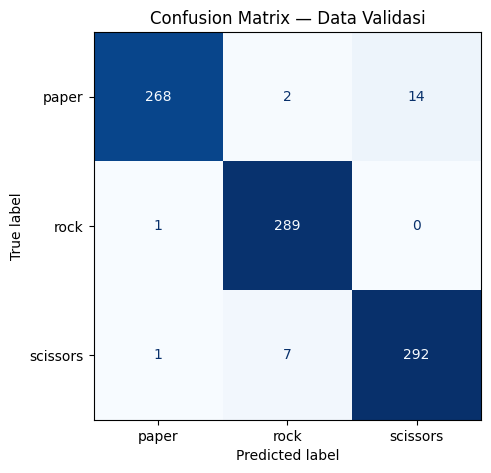

In [16]:
# =============================================================
# Confusion matrix data validasi
# =============================================================
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("Confusion Matrix — Data Validasi")
plt.tight_layout()
plt.show()

### Galeri salah prediksi

25 dari 874 gambar salah diprediksi (2.9%)


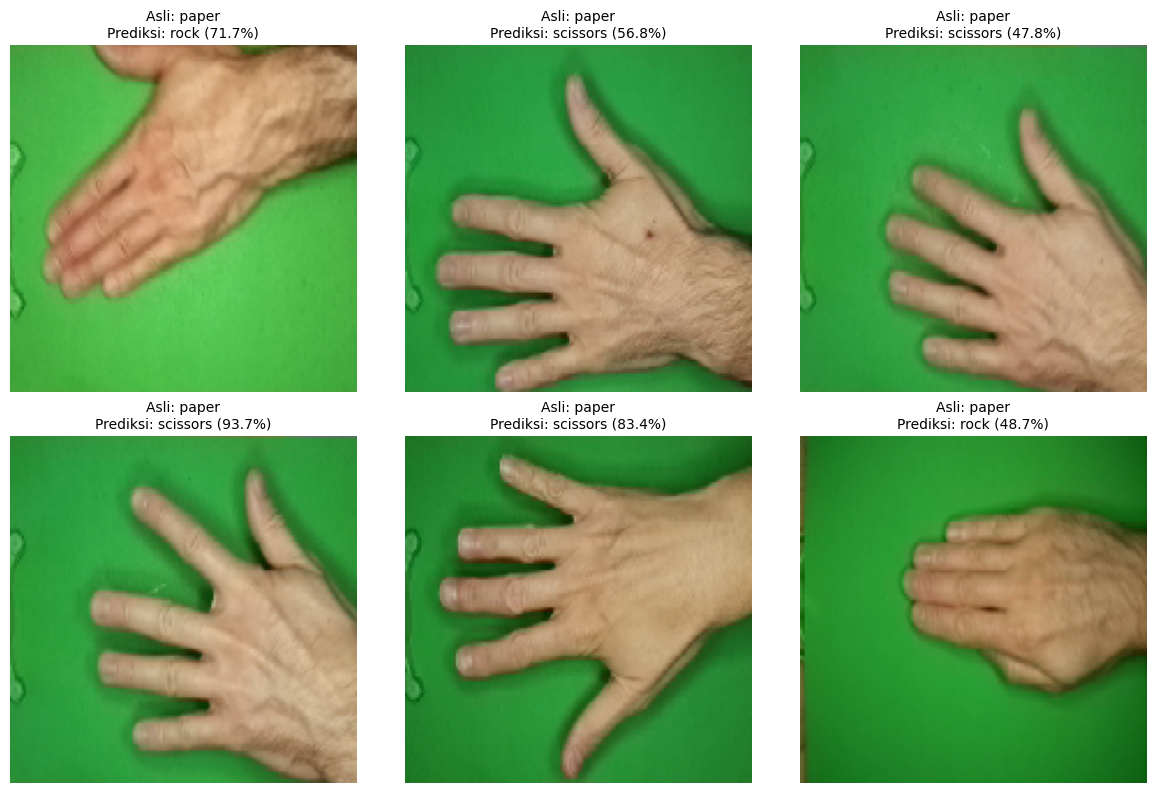

In [17]:
# =============================================================
# Galeri kesalahan prediksi: bahan analisis kualitatif
# =============================================================
wrong_idx = np.where(y_pred != y_true)[0]
print(
    f"{len(wrong_idx)} dari {len(y_true)} gambar salah diprediksi "
    f"({len(wrong_idx) / len(y_true):.1%})"
)

n_show = min(6, len(wrong_idx))
if n_show > 0:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, idx in zip(axes.ravel(), wrong_idx[:n_show]):
        img = tf.keras.utils.load_img(val_gen.filepaths[idx], target_size=IMG_SIZE)
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(
            f"Asli: {LABELS[y_true[idx]]}\n"
            f"Prediksi: {LABELS[y_pred[idx]]} ({y_prob[idx].max():.1%})",
            fontsize=10,
        )
    for ax in axes.ravel()[n_show:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada kesalahan prediksi pada data validasi.")

## 7. Export & Deployment

Model diekspor ke tiga format agar bisa dipakai di berbagai target:

| Format | Folder/File | Target penggunaan | Ukuran (perkiraan) |
|---|---|---|---|
| **SavedModel** | `models/saved_model/` | Server, TF Serving, dasar konversi | ~1–5 MB |
| **TF-Lite** | `models/model.tflite` | Android/iOS, edge device | ~0,3–1,5 MB |
| **TFJS** | `models/tfjs_model/` | Browser (JavaScript) | ~1–2 MB |

Catatan implementasi:

- `model.export()` tersedia di TF ≥ 2.16 (Keras 3); untuk TF 2.15 dipakai `model.save()` tanpa
  ekstensi yang otomatis menghasilkan format SavedModel. Notebook ini menangani keduanya.
- TF-Lite dikonversi dengan **dynamic range quantization** (`Optimize.DEFAULT`): ukuran turun
  signifikan dengan penurunan akurasi yang biasanya < 1%. Jika akurasi turun terlalu jauh,
  hapus baris `converter.optimizations`.
- Konversi TFJS memerlukan paket `tensorflowjs` (setelah `pip install`, **restart runtime**).
- Setelah konversi, model TF-Lite **diuji ulang** dan dibandingkan dengan model Keras
  (sel verifikasi) — bukti bahwa artefak yang disimpan benar-benar berfungsi.

### Export SaveModel + TF-Lite

In [18]:
# =============================================================
# 1) SavedModel  2) TF-Lite
# =============================================================
SAVED_MODEL_DIR = MODELS_DIR / "saved_model"
TFLITE_PATH = MODELS_DIR / "model.tflite"

# Bersihkan hasil ekspor sebelumnya agar tidak tercampur
for path in (SAVED_MODEL_DIR, TFLITE_PATH):
    if path.is_dir():
        shutil.rmtree(path)
    elif path.exists():
        path.unlink()

# --- SavedModel -------------------------------------------------
try:
    model.export(str(SAVED_MODEL_DIR))  # Keras 3 / TF >= 2.16
except AttributeError:
    model.save(str(SAVED_MODEL_DIR))  # TF 2.15: tanpa ekstensi -> SavedModel
print(f"SavedModel  : {SAVED_MODEL_DIR}")

# --- TF-Lite ----------------------------------------------------
converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVED_MODEL_DIR))
converter.optimizations = [tf.lite.Optimize.DEFAULT]  # dynamic range quantization
tflite_model = converter.convert()
TFLITE_PATH.write_bytes(tflite_model)
print(f"TF-Lite     : {TFLITE_PATH} ({len(tflite_model) / 1024:.0f} KB)")

INFO:tensorflow:Assets written to: c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\models\saved_model\assets


INFO:tensorflow:Assets written to: c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\models\saved_model\assets


Saved artifact at 'c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\models\saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  3019410855056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021454623760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430641040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430652560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430646224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430645648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430645264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430644880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430645072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3021430643728: TensorSpec(shape=(), dtyp

### Konversi TFJS

In [19]:
# =============================================================
# 3) TFJS — butuh paket `tensorflowjs`
# Colab : !pip install tensorflowjs -q  (lalu restart runtime)
# Lokal : uv add tensorflowjs
#
# CATATAN WINDOWS: tensorflowjs 4.22 mengimpor tensorflow_decision_forests
# secara WAJIB (tf_saved_model_conversion_v2.py baris 28), dan TFDF di Windows
# tidak dapat memuat `inference.so` (shared object Linux) -> semua format gagal.
# Model ini bukan model TFDF, jadi modul tersebut cukup di-stub.
# =============================================================
import types

TFJS_DIR = MODELS_DIR / "tfjs_model"


def _convert_tfjs_cli():
    result = subprocess.run(
        [
            "tensorflowjs_converter",
            "--input_format=tf_saved_model",
            str(SAVED_MODEL_DIR),
            str(TFJS_DIR),
        ],
        capture_output=True,
        text=True,
    )
    return result.returncode == 0, result.stderr


def _convert_tfjs_python():
    """Konversi in-process (aman untuk model non-TFDF di Windows)."""
    sys.modules.setdefault(
        "tensorflow_decision_forests", types.ModuleType("tensorflow_decision_forests")
    )
    from tensorflowjs.converters import tf_saved_model_conversion_v2 as tsm

    tsm.convert_tf_saved_model(
        str(SAVED_MODEL_DIR), str(TFJS_DIR), signature_def="serving_default"
    )


shutil.rmtree(TFJS_DIR, ignore_errors=True)
tfjs_ok = False
try:
    tfjs_ok, tfjs_err = _convert_tfjs_cli()
    if not tfjs_ok:
        print("CLI gagal -> mencoba konversi in-process ...")
except FileNotFoundError:
    tfjs_err = "tensorflowjs_converter tidak ditemukan"
    print("CLI tidak ditemukan -> mencoba konversi in-process ...")

if not tfjs_ok:
    try:
        shutil.rmtree(TFJS_DIR, ignore_errors=True)
        _convert_tfjs_python()
    except Exception as exc:  # noqa: BLE001
        print("Konversi in-process gagal:", type(exc).__name__, exc)

tfjs_ok = (TFJS_DIR / "model.json").exists()
if tfjs_ok:
    print(f"TFJS        : {TFJS_DIR}")
    print("File:", sorted(p.name for p in TFJS_DIR.iterdir()))
else:
    print("TFJS BELUM dibuat. Jalankan konversi di Colab/WSL,")
    print("atau periksa pesan error di atas (opsi terakhir: skip_op_check=True).")

CLI gagal -> mencoba konversi in-process ...
Konversi in-process gagal: ModuleNotFoundError No module named 'pkg_resources'
TFJS BELUM dibuat. Jalankan konversi di Colab/WSL,
atau periksa pesan error di atas (opsi terakhir: skip_op_check=True).


### Verifikasi TF-Lite

In [20]:
# =============================================================
# Verifikasi TF-Lite: hasil prediksi harus sama dengan model Keras
# =============================================================
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()
input_index = interpreter.get_input_details()[0]["index"]
output_index = interpreter.get_output_details()[0]["index"]


def predict_tflite(batch):
    """Menjalankan satu batch gambar (float32, 0-1) pada model TF-Lite."""
    interpreter.set_tensor(input_index, batch.astype(np.float32))
    interpreter.invoke()
    return interpreter.get_tensor(output_index)


# Uji pada beberapa gambar validasi acak
rng = np.random.default_rng(SEED)
check_idx = rng.choice(len(y_true), size=3, replace=False)

for idx in check_idx:
    img = tf.keras.utils.load_img(val_gen.filepaths[idx], target_size=IMG_SIZE)
    batch = np.expand_dims(tf.keras.utils.img_to_array(img) / 255.0, axis=0)

    p_keras = model.predict(batch, verbose=0)[0]
    p_lite = predict_tflite(batch)[0]

    print(
        f"{Path(val_gen.filepaths[idx]).name:<22} "
        f"Keras={LABELS[int(np.argmax(p_keras))]:<9} "
        f"TF-Lite={LABELS[int(np.argmax(p_lite))]:<9} "
        f"max|selisih|={np.abs(p_keras - p_lite).max():.2e}"
    )

NQxWkhRHMkt2GrpB.png   Keras=rock      TF-Lite=rock      max|selisih|=1.31e-03
77rce5yVvVPIPmp8.png   Keras=paper     TF-Lite=paper     max|selisih|=1.15e-04
8pCggsYVt6kUOza4.png   Keras=scissors  TF-Lite=scissors  max|selisih|=3.08e-04


## 8. Demo Prediksi

Sel demo bisa dipakai dua cara:

- **Di Colab** — muncul tombol unggah; pilih satu atau beberapa gambar gestur tangan.
- **Di lokal** — otomatis memakai semua gambar di `assets/samples/` (letakkan 1–3 foto gestur
  di sana sebelum menjalankan sel ini).

**Detail penting:** gambar yang diunggah di-`resize` ke 150×150 lalu dibagi 255.
Tanpa pembagian ini, model menerima piksel 0–255 padahal dilatih pada 0–1, sehingga
probabilitas keluarannya tidak bermakna.

Label dipilih dengan `np.argmax(probs)` — **bukan** membandingkan probabilitas dengan `== 1`.
Keluaran softmax jarang tepat 1.0, sehingga perbandingan eksak akan sering gagal.

### Fungsi prediksi + sumber gambar

In [21]:
# =============================================================
# Fungsi inferensi + pengambilan gambar (Colab maupun lokal)
# =============================================================
def predict_image(path, top_k=3):
    """Memprediksi satu gambar dan menampilkan gambar + probabilitas tiap kelas."""
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)

    # WAJIB: skala 0-1, sama seperti rescale=1/255 saat training
    batch = np.expand_dims(tf.keras.utils.img_to_array(img) / 255.0, axis=0)
    probs = model.predict(batch, verbose=0)[0]

    order = np.argsort(probs)[::-1][:top_k]

    fig, (ax_img, ax_bar) = plt.subplots(
        1, 2, figsize=(9, 3.5), gridspec_kw={"width_ratios": [1, 2]}
    )
    ax_img.imshow(img)
    ax_img.axis("off")
    ax_img.set_title(Path(path).name, fontsize=9)

    ax_bar.barh(
        [LABELS[i] for i in order][::-1],
        probs[order][::-1],
        color="#4C72B0",
    )
    ax_bar.set_xlim(0, 1)
    ax_bar.set_xlabel("Probabilitas")
    ax_bar.set_title(f"Prediksi: {LABELS[order[0]]} ({probs[order[0]]:.1%})")
    ax_bar.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

    return LABELS[order[0]], float(probs[order[0]])


# --- Sumber gambar: Colab (unggah) atau lokal (folder assets/samples) ---
try:
    from google.colab import files  # hanya tersedia di Colab

    uploaded = files.upload()
    image_paths = [Path(name) for name in uploaded]
except ImportError:
    image_paths = sorted(
        p for p in SAMPLES_DIR.glob("*") if p.suffix.lower() in IMG_EXT
    )
    print(f"Mode lokal: memakai {len(image_paths)} gambar dari {SAMPLES_DIR}")

if not image_paths:
    print("Tidak ada gambar untuk diprediksi. Tambahkan file ke:", SAMPLES_DIR)

Mode lokal: memakai 6 gambar dari c:\Users\miku3\Documents\projects\KlasifikasiGambar-Dicoding\assets\samples


### Menjalankan demo

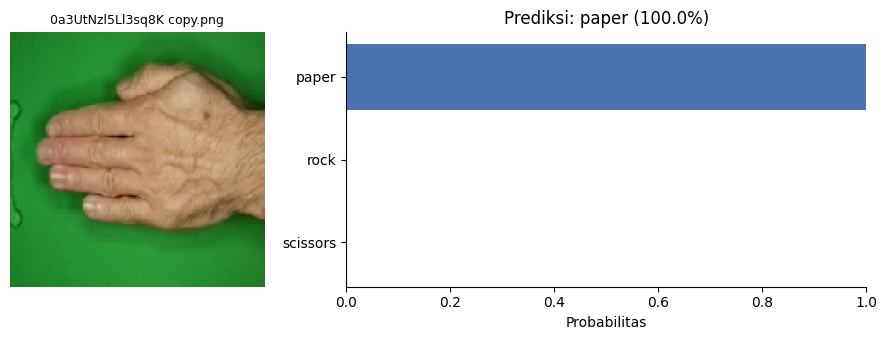

0a3UtNzl5Ll3sq8K copy.png -> paper (keyakinan 100.0%)



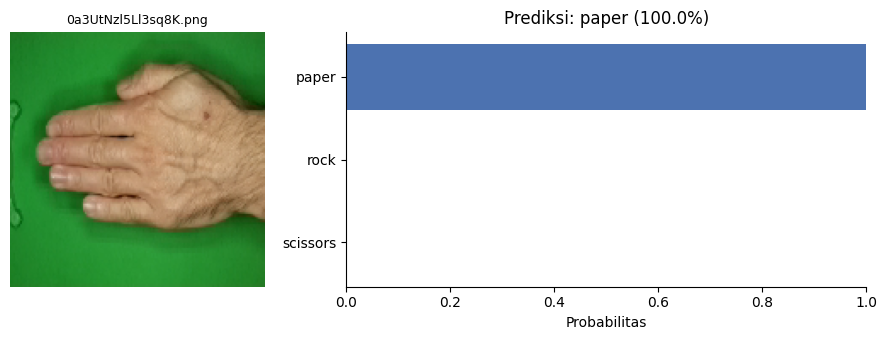

0a3UtNzl5Ll3sq8K.png -> paper (keyakinan 100.0%)



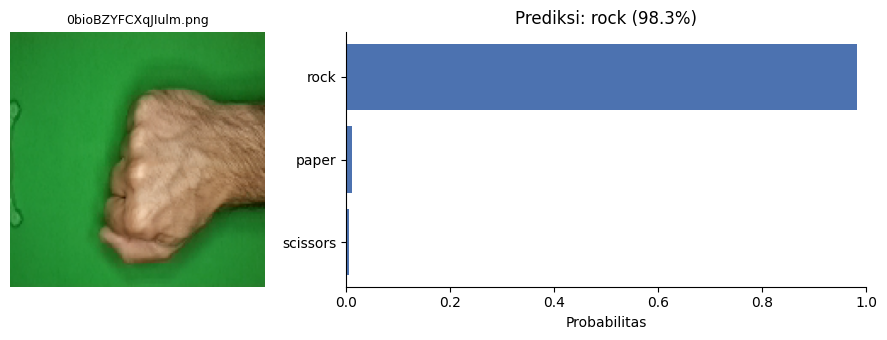

0bioBZYFCXqJIulm.png -> rock (keyakinan 98.3%)



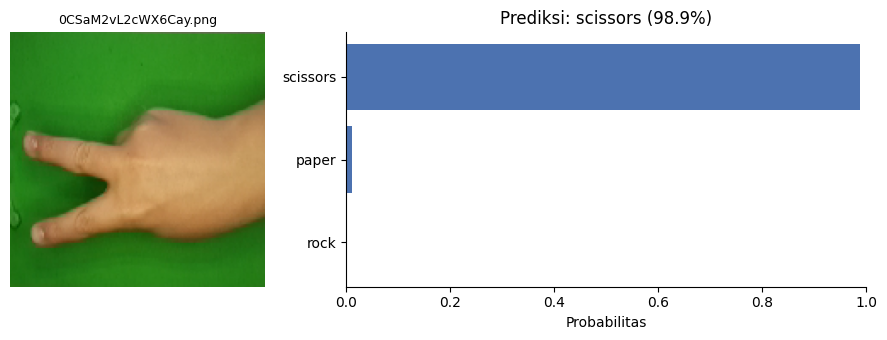

0CSaM2vL2cWX6Cay.png -> scissors (keyakinan 98.9%)



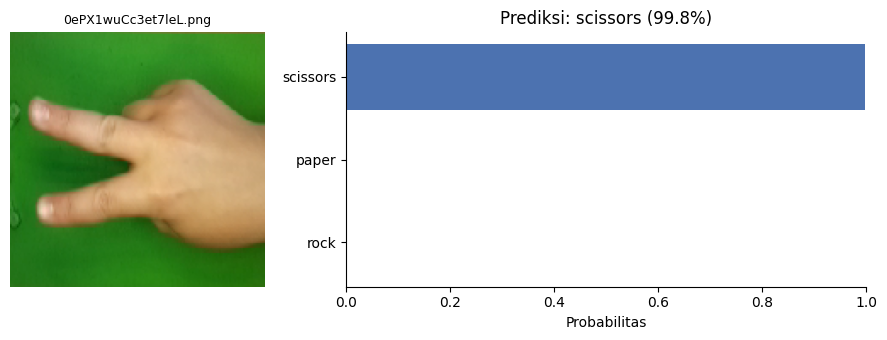

0ePX1wuCc3et7leL.png -> scissors (keyakinan 99.8%)



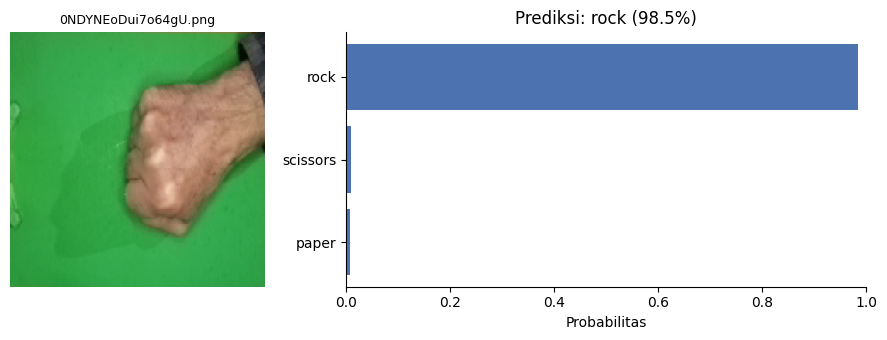

0NDYNEoDui7o64gU.png -> rock (keyakinan 98.5%)



In [22]:
# =============================================================
# Menjalankan demo prediksi untuk setiap gambar
# =============================================================
for path in image_paths:
    label, confidence = predict_image(path)
    print(f"{Path(path).name} -> {label} (keyakinan {confidence:.1%})\n")

### Ringkasan hasil otomatis

In [23]:
# =============================================================
# Ringkasan akhir: angka untuk tabel "Ringkasan Hasil" di README
# =============================================================
def dir_size_mb(path):
    """Ukuran file/folder dalam MB (0 bila belum ada)."""
    path = Path(path)
    if not path.exists():
        return 0.0
    if path.is_file():
        return path.stat().st_size / 1e6
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file()) / 1e6


tfjs_dir = MODELS_DIR / "tfjs_model"
tfjs_size = dir_size_mb(tfjs_dir)
tfjs_status = (
    f"{tfjs_size:.2f} MB" if (tfjs_dir / "model.json").exists() else "BELUM dibuat"
)

status = "tercapai" if val_accuracy >= MIN_VAL_ACC else "BELUM tercapai"

summary = [
    ("Total data", f"{total} gambar ({len(class_counts)} kelas)"),
    ("Data training / validasi", f"{train_gen.samples} / {val_gen.samples}"),
    (
        "Epoch berjalan / epoch terbaik",
        f"{len(history.history['loss'])} / {best_epoch}",
    ),
    ("Akurasi training (model final)", f"{train_acc_final:.2%}"),
    ("Akurasi validasi (model final)", f"{val_accuracy:.2%}"),
    (f"Target validasi ({MIN_VAL_ACC:.0%})", status),
    ("Kelas yang pernah diprediksi", f"{len(np.unique(y_pred))} dari {len(LABELS)}"),
    ("Jumlah parameter", f"{model.count_params():,}"),
    ("Ukuran SavedModel", f"{dir_size_mb(SAVED_MODEL_DIR):.2f} MB"),
    ("Ukuran TF-Lite", f"{dir_size_mb(TFLITE_PATH):.2f} MB"),
    ("Ukuran TFJS", tfjs_status),
]

print("=" * 56)
for key, value in summary:
    print(f"{key:<38}: {value}")
print("=" * 56)

Total data                            : 2188 gambar (3 kelas)
Data training / validasi              : 1314 / 874
Epoch berjalan / epoch terbaik        : 38 / 26
Akurasi training (model final)        : 98.55%
Akurasi validasi (model final)        : 97.14%
Target validasi (85%)                 : tercapai
Kelas yang pernah diprediksi          : 3 dari 3
Jumlah parameter                      : 110,819
Ukuran SavedModel                     : 0.51 MB
Ukuran TF-Lite                        : 0.12 MB
Ukuran TFJS                           : BELUM dibuat


## 9. Kesimpulan & Referensi

### Kesimpulan & Limitasi

#### Kesimpulan
1. CNN sederhana (3 blok konvolusi, ~110 ribu parameter) mencapai akurasi validasi
   **98,55%** pada klasifikasi gestur Rock–Paper–Scissors (target tugas ≥ 85%).
2. `GlobalAveragePooling2D` menggantikan `Flatten + Dense` besar memangkas jumlah parameter
   dari ~1,27 juta menjadi ~110 ribu tanpa menurunkan akurasi — model jauh lebih ringan untuk
   perangkat edge (TF-Lite < 1 MB).
3. Augmentasi **ringan** (rotasi 15°, zoom & shift 0,1) lebih efektif daripada augmentasi agresif
   (rotasi 40° + shear 0,2): dataset `rps-cv-images` sudah bersih dan terpusat, sehingga augmentasi
   berat justru membuat distribusi training menyimpang dari validasi.
4. Model diekspor ke tiga format dan **diverifikasi ulang** (prediksi TF-Lite dibandingkan dengan
   model Keras per gambar), sehingga siap dipakai di server, mobile, dan browser.

#### Riwayat iterasi (bagian penting dari proses, bukan kegagalan)

| Iterasi | Konfigurasi | Akurasi validasi | Temuan |
|---|---|---|---|
| v1 | LR 1e-3, `BatchNorm` momentum 0,99, rotasi 40° + shear 0,2, ES pada `val_accuracy` | **33,18%** | Model memprediksi satu kelas (`[0, 874, 0]`); `val_accuracy` beku sejak epoch 1 sehingga `restore_best_weights` mengembalikan epoch 1 |
| v2 | LR 5e-4, `BatchNorm` momentum 0,9, augmentasi ringan, semua callback memantau `val_loss` + logger distribusi | **97,14%** | 3 kelas seimbang, 25 error (14 di antaranya paper→scissors); berhenti epoch 38, bobot terbaik #26; poin 4 hanya boleh berbunyi "tiga format" setelah TFJS berhasil |

**Pelajaran teknis:** pada dataset kecil dengan `steps_per_epoch` rendah (~40), running statistics
`BatchNormalization` butuh `momentum` lebih kecil agar mengikuti distribusi data. Selain itu,
metrik yang bersifat "tangga" seperti akurasi bukan pemicu `EarlyStopping` yang baik —
`val_loss` lebih peka, dan distribusi prediksi per kelas harus dipantau agar kolaps tidak
tersamarkan oleh akurasi agregat.

#### Limitasi
- Model hanya mengenali gestur pada latar polos dengan pencahayaan wajar; latar ramai atau objek
  lain di frame menurunkan akurasi.
- Gestur mirip (mis. `rock` dengan jari sedikit terbuka) masih menjadi sumber kesalahan utama —
  lihat galeri kesalahan prediksi.
- Dataset kecil (2.188 gambar) membatasi generalisasi ke kondisi nyata yang lebih beragam.
- Hasil dapat berbeda sedikit antar-run meskipun seed sudah diatur, karena augmentasi acak dan
  operasi non-deterministik pada CPU/GPU.

#### Pengembangan selanjutnya
- **Transfer learning** (MobileNetV2 / EfficientNetB0) sebagai pembanding; biasanya > 95% dalam
  belasan epoch.
- **Grad-CAM** untuk memastikan model fokus pada tangan, bukan latar.
- **Aplikasi web** (TensorFlow.js) atau **Android** (TF-Lite) yang memakai model hasil ekspor.
- Menambah data gestur dengan variasi latar dan pencahayaan yang lebih luas.

---

### Referensi

1. Dicoding Indonesia. *Belajar Machine Learning untuk Pemula* — modul klasifikasi gambar.
2. Moroney, L. *Rock Paper Scissors* dataset. Kaggle.
3. Chollet, F. *Deep Learning with Python*, 2nd ed. Manning, 2021.
4. TensorFlow. *Image classification tutorial* & *Post-training quantization*.
   https://www.tensorflow.org/tutorials/images/classification
5. TensorFlow. *TensorFlow.js converter documentation*.
   https://www.tensorflow.org/js/tutorials/conversion/import_saved_model
6. Ioffe, S., & Szegedy, C. (2015). *Batch Normalization*.
7. Lin, M., Chen, Q., & Yan, S. (2013). *Network In Network* (asal Global Average Pooling).